# From lens design to the wafer: aberrations across the scanner slit

Notebook 24 traced projection lenses and showed their Zernikes, distortion
and telecentricity over the field. Here the lens is the dioptric ArF water
immersion design of Zeiss patent US 7,187,503 B2 (`zeiss_arfi_lens()`:
193.368 nm, NA 1.35, 8x, image field Ø 14 mm, 11 aspheres).
Notebook 17 put hand picked Zernikes into the lithography toolbox. This
notebook connects the two with `pyoptics.litho.lens`:

1. **Lens to projector.** `lens_aberrations()` fits Fringe Zernikes to the
   ray traced OPD on the pupil coordinates of `Projector` and returns the
   distortion, the telecentricity and the placement of a small feature;
   `projector_from_system()` builds the projector directly.
2. **The scanner slit.** A 13 × 4 mm slit fits into the 14 mm image field.
   Zernikes, placement and telecentricity over the slit, and what a scanner
   can correct (translation, magnification, rotation).
3. **CD, placement and best focus across the slit** for dense and isolated
   lines, static and scanned (`through_slit()`), and Bossung curves at the
   slit centre and edge.
4. **Zernike sensitivities** (`zernike_sensitivity()`): which aberration
   moves CD, placement and best focus of which pattern, and why (parities,
   two and three beam imaging).
5. **An aberration budget** (`predict()`): the sensitivities applied to the
   lens Zernikes, against the full simulation across the slit.

The lens is a published design example, not a production lens. Its
wavefront is close to the diffraction limit (about 20 mλ RMS), but it is
not telecentric on the wafer side (up to 40 mrad at the edge of the field),
and its smaller 8x field gives a smaller slit than the 26 mm of 4x
scanners. Everything runs at the lens's own conditions: ArF (193.368 nm),
water immersion, NA 1.35, vectorial imaging. Notebook 24 shows the same
steps for Caldwell's dry KrF lens (NA 0.56).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Rectangle

from pyoptics.litho import Illumination, MaskLayout, ThinMask, Projector, LithoSimulation, lens
from pyoptics.raytrace import WATER_ARF, zeiss_arfi_lens

plt.rcParams.update({"figure.dpi": 80, "image.origin": "lower", "font.size": 11})

system = zeiss_arfi_lens()             # lengths in mm, ArF 193.368 nm, water immersion
WL = system.wavelength*1e6             # simulation length unit: nm
NA = lens.lens_NA(system)
m = system.paraxial().magnification
print(f"wavelength {WL:.1f} nm, image side NA {NA:.4f}, magnification {m:.5f}")

SLIT_X, SLIT_Y = 6.5, 2.0              # half widths of the 13 x 4 mm slit (wafer side)
R_FIELD = 7.0                          # image field radius

wavelength 193.4 nm, image side NA 1.3483, magnification -0.12500


## 1. Lens to projector

The ray tracer gives the OPD on its own pupil coordinates (ray aiming at the
stop). `Projector` describes the pupil by the transverse wave vector of a
plane wave in image space, $P = n'\,\mathbf d_{xy}/\mathrm{NA}$. The fit
therefore traces a grid of rays, takes the direction $\mathbf d$ of each ray
in image space relative to the chief ray and fits Fringe Zernikes at
$P = n'(\mathbf d - \mathbf d_\mathrm{chief})_{xy}/\mathrm{NA}$. The
coefficients are in waves and go straight into `Projector(zernikes=...)`,
whose pupil phase is $2\pi W$ (the same sign convention as
`raytrace.System.pupil()`).

Three numbers are not part of the pupil:

- the **distortion**, the chief ray's image point minus the paraxial image
  point $m\,y_\mathrm{object}$,
- the **telecentricity**, the chief ray direction: in a plane defocused by
  $z$ the image moves sideways by $z\tan\theta_\mathrm{chief}$,
- the **placement** of a small feature: the distortion plus the shift by the
  Zernike tilts $Z_2, Z_3$ (relative to the chief ray),
  $-(c_2, c_3)\,\lambda/\mathrm{NA}$, which to first order is the shift of the
  PSF centroid. A pattern dependent part comes on top of this (coma, see
  section 4).

field (0.0, 0.0): fit residual 1.7 mλ RMS, distortion (0, 0) nm, telecentricity (0.00, 0.00) mrad, placement (-0, -0) nm
field (6.5, 0.0): fit residual 6.1 mλ RMS, distortion (-80, 0) nm, telecentricity (37.33, 0.00) mrad, placement (-76, -0) nm
field (6.5, 2.0): fit residual 6.7 mλ RMS, distortion (-108, -33) nm, telecentricity (37.30, 11.48) mrad, placement (-107, -33) nm


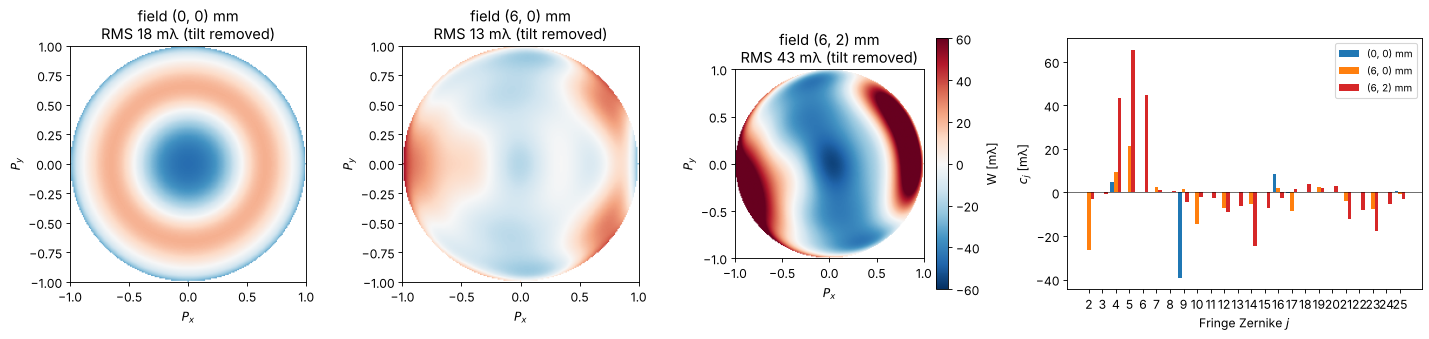

In [2]:
fields = [(0.0, 0.0), (SLIT_X, 0.0), (SLIT_X, SLIT_Y)]
abers = [lens.lens_aberrations(system, f, n_terms=36, N=48) for f in fields]
P = np.linspace(-1, 1, 201)
PX, PY = np.meshgrid(P, P)
inside = PX**2 + PY**2 <= 1

fig, axes = plt.subplots(1, 4, figsize=(18, 4.2), gridspec_kw={"width_ratios": [1, 1, 1, 1.5]})
for ax, ab in zip(axes, abers):
    proj = Projector(NA, WL, n=WATER_ARF, zernikes={j: c for j, c in ab.zernikes.items() if j > 3})
    W = np.where(inside, proj.pupil_phase(PX, PY)/(2*np.pi), np.nan)*1000
    im = ax.imshow(W, extent=(-1, 1, -1, 1), cmap="RdBu_r", vmin=-60, vmax=60)
    rms = np.nanstd(W)
    ax.set_title(f"field ({ab.field[0]:.0f}, {ab.field[1]:.0f}) mm\nRMS {rms:.0f} mλ (tilt removed)")
    ax.set_xlabel("$P_x$"); ax.set_ylabel("$P_y$")
plt.colorbar(im, ax=axes[2], label="W [mλ]")
idx = np.arange(2, 26)
for k, (ab, c) in enumerate(zip(abers, ("C0", "C1", "C3"))):
    axes[3].bar(idx + (k - 1)*0.27, [1000*ab.zernikes[j] for j in idx], 0.27, color=c,
                label=f"({ab.field[0]:.0f}, {ab.field[1]:.0f}) mm")
axes[3].set_xticks(idx); axes[3].set_xlabel("Fringe Zernike $j$"); axes[3].set_ylabel("$c_j$ [mλ]")
axes[3].axhline(0, color="k", lw=0.5); axes[3].legend(fontsize=9)
fig.tight_layout()

for ab in abers:
    print(f"field {ab.field}: fit residual {1000*ab.rms_residual:.1f} mλ RMS, distortion "
          f"({ab.distortion[0]:.0f}, {ab.distortion[1]:.0f}) nm, telecentricity "
          f"({1000*ab.telecentricity[0]:.2f}, {1000*ab.telecentricity[1]:.2f}) mrad, placement "
          f"({ab.placement[0]:.0f}, {ab.placement[1]:.0f}) nm")

On axis only the rotationally symmetric terms remain ($Z_4$, $Z_9$, $Z_{16}$,
$Z_{25}$: residual spherical aberration balanced with defocus). At the slit
edge field curvature ($Z_4$), astigmatism ($Z_5$), coma ($Z_7$) and higher
orders appear. 36 Fringe Zernikes describe the wavefront to a few
milliwaves.

The fit is checked in the tests against the ray traced PSF: the centroid
of the PSF lies at the predicted placement.

## 2. The scanner slit

A scanner exposes through a slit, here 13 × 4 mm on the wafer, which just
fits into the 14 mm image field of the lens; mask and wafer move along
$y$ (the scan direction) at speeds in the ratio of the magnification.
Every point of the wafer is exposed by all scan positions $y$ of the slit
at its slit position $x$, so the aberrations that matter for imaging vary
along $x$ only, and what varies along $y$ is averaged.

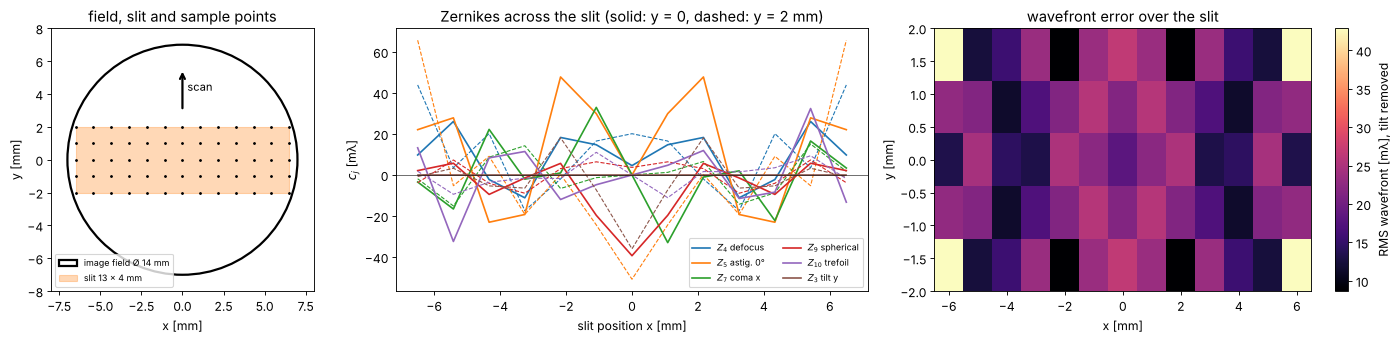

In [3]:
xs = np.linspace(-SLIT_X, SLIT_X, 13)
ys = np.linspace(-SLIT_Y, SLIT_Y, 5)
grid = [[lens.lens_aberrations(system, (x, y), n_terms=36, N=32) for x in xs] for y in ys]
Z = np.array([[[ab.zernikes[j] for j in range(2, 37)] for ab in row] for row in grid])*1000  # (y, x, j)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.4), gridspec_kw={"width_ratios": [1, 1.6, 1.6]})
ax = axes[0]
ax.add_patch(Circle((0, 0), R_FIELD, fill=False, lw=2, label="image field Ø 14 mm"))
ax.add_patch(Rectangle((-SLIT_X, -SLIT_Y), 2*SLIT_X, 2*SLIT_Y, alpha=0.3, color="C1", label="slit 13 × 4 mm"))
X, Y = np.meshgrid(xs, ys)
ax.plot(X, Y, "k.", ms=3)
ax.annotate("", xy=(0, 5.5), xytext=(0, 3), arrowprops=dict(arrowstyle="->", lw=2))
ax.text(0.3, 4.2, "scan", fontsize=10)
ax.set_aspect("equal"); ax.set_xlim(-8, 8); ax.set_ylim(-8, 8)
ax.set_xlabel("x [mm]"); ax.set_ylabel("y [mm]"); ax.legend(fontsize=8, loc="lower left")
ax.set_title("field, slit and sample points")
labels = {4: "$Z_4$ defocus", 5: "$Z_5$ astig. 0°", 7: "$Z_7$ coma x", 9: "$Z_9$ spherical",
          10: "$Z_{10}$ trefoil", 3: "$Z_3$ tilt y"}
for k, (j, name) in enumerate(labels.items()):
    i = j - 2
    axes[1].plot(xs, Z[len(ys)//2, :, i], "-", color=f"C{k}", label=name)
    axes[1].plot(xs, Z[-1, :, i], "--", color=f"C{k}", lw=1)
axes[1].set_xlabel("slit position x [mm]"); axes[1].set_ylabel("$c_j$ [mλ]")
axes[1].set_title("Zernikes across the slit (solid: y = 0, dashed: y = 2 mm)")
axes[1].legend(fontsize=8, ncol=2); axes[1].axhline(0, color="k", lw=0.5)
W_rms = np.zeros((len(ys), len(xs)))
for r, row in enumerate(grid):
    for c, ab in enumerate(row):
        proj = Projector(NA, WL, n=WATER_ARF, zernikes={j: v for j, v in ab.zernikes.items() if j > 3})
        W_rms[r, c] = 1000*np.std(proj.pupil_phase(PX[inside], PY[inside])/(2*np.pi))
im = axes[2].imshow(W_rms, extent=(xs[0], xs[-1], ys[0], ys[-1]), aspect="auto", cmap="magma")
plt.colorbar(im, ax=axes[2], label="RMS wavefront [mλ], tilt removed")
axes[2].set_xlabel("x [mm]"); axes[2].set_ylabel("y [mm]"); axes[2].set_title("wavefront error over the slit")
fig.tight_layout()

### Placement and what the scanner corrects

The chief ray distortion of the design grows towards the corners of the
slit (up to about 110 nm, pointing inwards), and the image of a small
feature, which lands where the PSF centroid is, follows it closely: coma
and the higher order tilts of this well corrected lens add only a few nm.
A scanner corrects translation, magnification (along $x$ in the lens,
along $y$ by the scan speed) and rotation, which `linear_correction()`
fits to the placements of the sample points. Here this removes most of
the error: what is left is the nonlinear part, up to about 30 nm in the
corners of the slit. In a production lens the residual is a few nm; this
design was not optimized for it.

fitted magnification error along x: -12.0 nm/mm = -1.2e-05
image shift by telecentricity per 100 nm of defocus at the slit edge: 3.90 nm


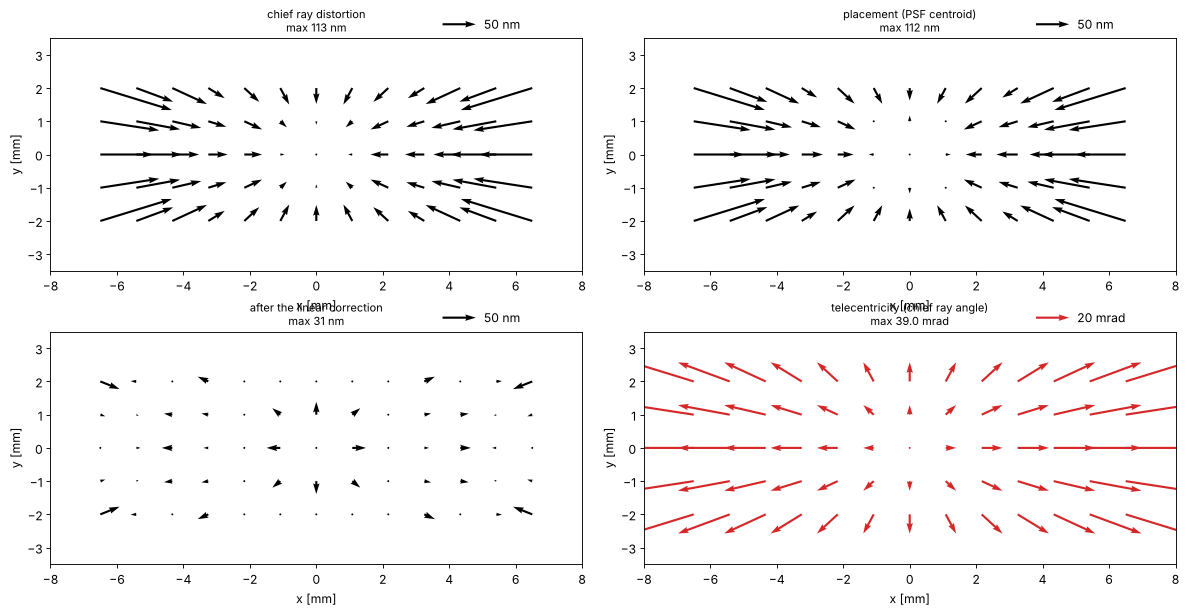

In [4]:
flat = [ab for row in grid for ab in row]
corr = lens.linear_correction(flat)
F = np.array([ab.field for ab in flat])
D_chief = np.array([ab.distortion for ab in flat])
D = np.array([ab.placement for ab in flat])
D_res = D - np.array([corr(*f) for f in F])
T = 1000*np.array([ab.telecentricity for ab in flat])

fig, axes = plt.subplots(2, 2, figsize=(15, 7.5))
axes = axes.ravel()
for ax, d, title in zip(axes, (D_chief, D, D_res),
                        ("chief ray distortion", "placement (PSF centroid)", "after the linear correction")):
    q = ax.quiver(F[:, 0], F[:, 1], d[:, 0], d[:, 1], angles="xy", scale_units="xy", scale=50, width=0.004)
    ax.quiverkey(q, 0.8, 1.06, 50, "50 nm", labelpos="E")
    ax.set_title(f"{title}\nmax {np.max(np.hypot(*d.T)):.0f} nm", fontsize=10)
    ax.set_xlim(-8, 8); ax.set_ylim(-3.5, 3.5); ax.set_aspect("equal"); ax.set_xlabel("x [mm]")
    ax.set_ylabel("y [mm]")
q = axes[3].quiver(F[:, 0], F[:, 1], T[:, 0], T[:, 1], angles="xy", scale_units="xy", scale=20, width=0.004, color="C3")
axes[3].quiverkey(q, 0.8, 1.06, 20, "20 mrad", labelpos="E")
axes[3].set_title(f"telecentricity (chief ray angle)\nmax {np.max(np.hypot(*T.T)):.1f} mrad", fontsize=10)
axes[3].set_xlim(-8, 8); axes[3].set_ylim(-3.5, 3.5); axes[3].set_aspect("equal"); axes[3].set_xlabel("x [mm]")
axes[3].set_ylabel("y [mm]")
fig.tight_layout()
mag_x = corr(1.0, 0.0)[0] - corr(0.0, 0.0)[0]
print(f"fitted magnification error along x: {mag_x:.1f} nm/mm = {mag_x*1e-6:.1e}")
print(f"image shift by telecentricity per 100 nm of defocus at the slit edge: {0.1*np.max(np.hypot(*T.T)):.2f} nm")

The chief ray in the water is tilted by up to 40 mrad at the edge of
the slit, pointing outwards: a defocus of 100 nm moves the image by 4 nm
there. This is the one property in which the patent design is far from a
scanner lens, whose telecentricity is a few mrad; the focus dependent
placement it causes shows up below.

## 3. CD, placement and best focus across the slit

Three patterns at ArF immersion, binary mask, conventional illumination
σ = 0.6 (threshold 0.3, dose to size at the slit centre):

- dense vertical lines, 80 nm lines and spaces ($k_1 = 0.56$): the cut
  goes along $x$, so $x$ tilt and $x$ coma move them,
- the same lines horizontal: the cut goes along $y$,
- semi-isolated vertical lines, 80 nm at a pitch of 480 nm.

`through_slit()` computes, at each slit position $x$, the cuts through focus
for all scan positions $y$ with the Zernikes, placement and telecentricity
of the lens there, and averages them: the image a scanned wafer point
receives. With only $y = 0$ it is the static image. Placements are after the
linear correction of section 2.

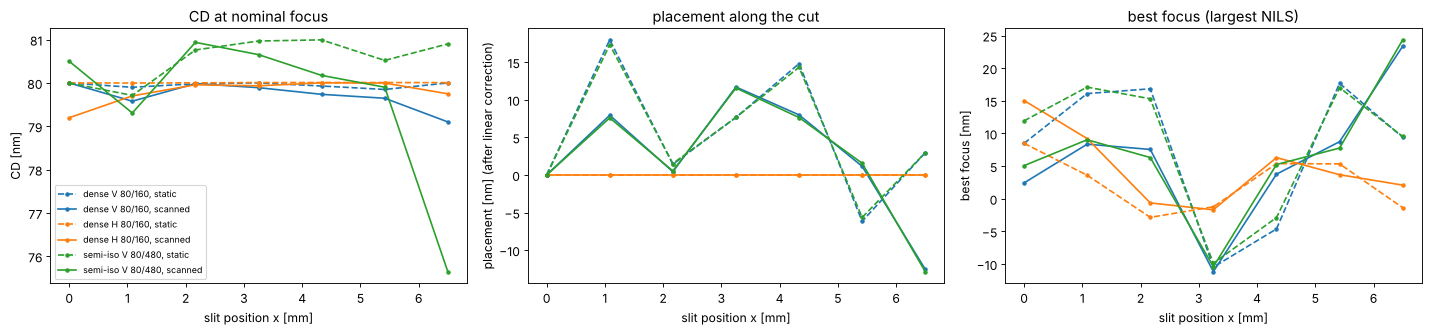

In [5]:
ill = Illumination.conventional(0.6, n_samples=21)
centre = lens.projector_from_system(system, (0.0, 0.0), n=WATER_ARF)
patterns = {"dense V 80/160": MaskLayout.lines_spaces(160.0, 80.0),
            "dense H 80/160": MaskLayout.lines_spaces(160.0, 80.0, orientation="x"),
            "semi-iso V 80/480": MaskLayout.lines_spaces(480.0, 80.0)}
foci = np.linspace(-150, 150, 21)
x_slit = np.linspace(0, SLIT_X, 7)
y_scan = np.linspace(-SLIT_Y, SLIT_Y, 5)
sims, doses, slit = {}, {}, {}
for name, layout in patterns.items():
    sims[name] = LithoSimulation(layout, ThinMask.binary(), ill, centre)
    doses[name] = sims[name].dose_to_size(threshold=0.3)
    for scan, y in (("static", [0.0]), ("scanned", y_scan)):
        slit[name, scan] = lens.through_slit(sims[name], system, x_slit, y=y, dose=doses[name], foci=foci,
                                             correction=corr)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.3))
for k, name in enumerate(patterns):
    for scan, ls in (("static", "--"), ("scanned", "-")):
        r = slit[name, scan]
        lab = f"{name}, {scan}"
        axes[0].plot(r.x, r.cd, ls, color=f"C{k}", marker="o", ms=3, label=lab)
        axes[1].plot(r.x, r.placement, ls, color=f"C{k}", marker="o", ms=3, label=lab)
        axes[2].plot(r.x, r.best_focus, ls, color=f"C{k}", marker="o", ms=3, label=lab)
for ax, yl in zip(axes, ("CD [nm]", "placement [nm] (after linear correction)", "best focus [nm]")):
    ax.set_xlabel("slit position x [mm]"); ax.set_ylabel(yl)
axes[0].legend(fontsize=8)
axes[0].set_title("CD at nominal focus"); axes[1].set_title("placement along the cut"); axes[2].set_title("best focus (largest NILS)")
fig.tight_layout()

What the curves show:

- **CD.** The dense lines change by less than 1 nm across the slit, the
  semi-isolated lines by about 1 nm static and up to 4 nm scanned at the
  edge. Dense lines at this pitch are imaged by three beams, isolated
  lines by a continuous spectrum that samples the whole pupil, so they
  feel more of the wavefront (see section 4).
- **Placement.** The horizontal lines don't move: their cut is along $y$,
  and the lens is mirror symmetric about $y = 0$, so the static image has no
  $y$ shift, and the scanned image averages $+y$ and $-y$. Vertical lines
  move by the residual distortion (up to 18 nm static, after the linear
  correction) plus a small pattern dependent coma shift; dense and
  semi-isolated lines move almost alike here, because the coma of this lens
  is small.
- **Best focus** (the focus of the largest NILS) follows the field
  curvature ($Z_4$) and, pattern dependent, spherical aberration and
  astigmatism: it varies by about 35 nm across the slit, and at the edge
  vertical and horizontal lines focus up to 20 nm apart ($Z_5$).
- **Scanning** averages the images over $y$. Where placement or focus vary
  along $y$, the averaged image is blurred (image fading), which costs CD
  and process window; the semi-isolated lines at the slit edge lose 4 nm
  of CD this way, because their placement and focus change over the 4 mm
  of the slit along the scan.

### Bossung curves at the slit centre and edge

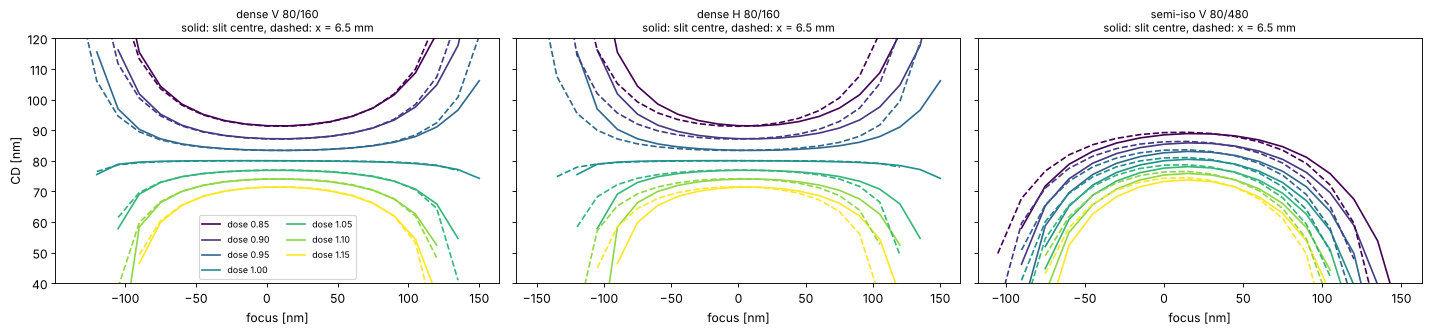

In [6]:
doses_rel = np.linspace(0.85, 1.15, 7)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.3), sharey=True)
for ax, name in zip(axes, patterns):
    for field, ls in (((0.0, 0.0), "-"), ((SLIT_X, 0.0), "--")):
        sim = sims[name].with_(projector=lens.projector_from_system(system, field, n=WATER_ARF))
        fem = sim.fem(foci, doses[name]*doses_rel, 0.3)
        for i, D in enumerate(doses_rel):
            ax.plot(foci, fem[i], ls, color=plt.cm.viridis(i/(len(doses_rel) - 1)),
                    label=f"dose {D:.2f}" if ls == "-" else None)
    ax.set_title(f"{name}\nsolid: slit centre, dashed: x = {SLIT_X:.1f} mm", fontsize=10)
    ax.set_xlabel("focus [nm]"); ax.set_ylim(40, 120)
axes[0].set_ylabel("CD [nm]"); axes[0].legend(fontsize=8, ncol=2)
fig.tight_layout()

The Bossung curves at the slit centre and edge nearly coincide: the
wavefront of the lens is close to the diffraction limit everywhere in the
slit. At the edge the curves of the semi-isolated lines shift by some nm in
focus and tilt slightly, so the common process window of centre and edge
is a little smaller than that of either point.

dense V 80/160: largest |dCD/dc_j| 3.6e-13 nm per wave
semi-iso V 80/480: largest |dCD/dc_j| 3.6e-13 nm per wave


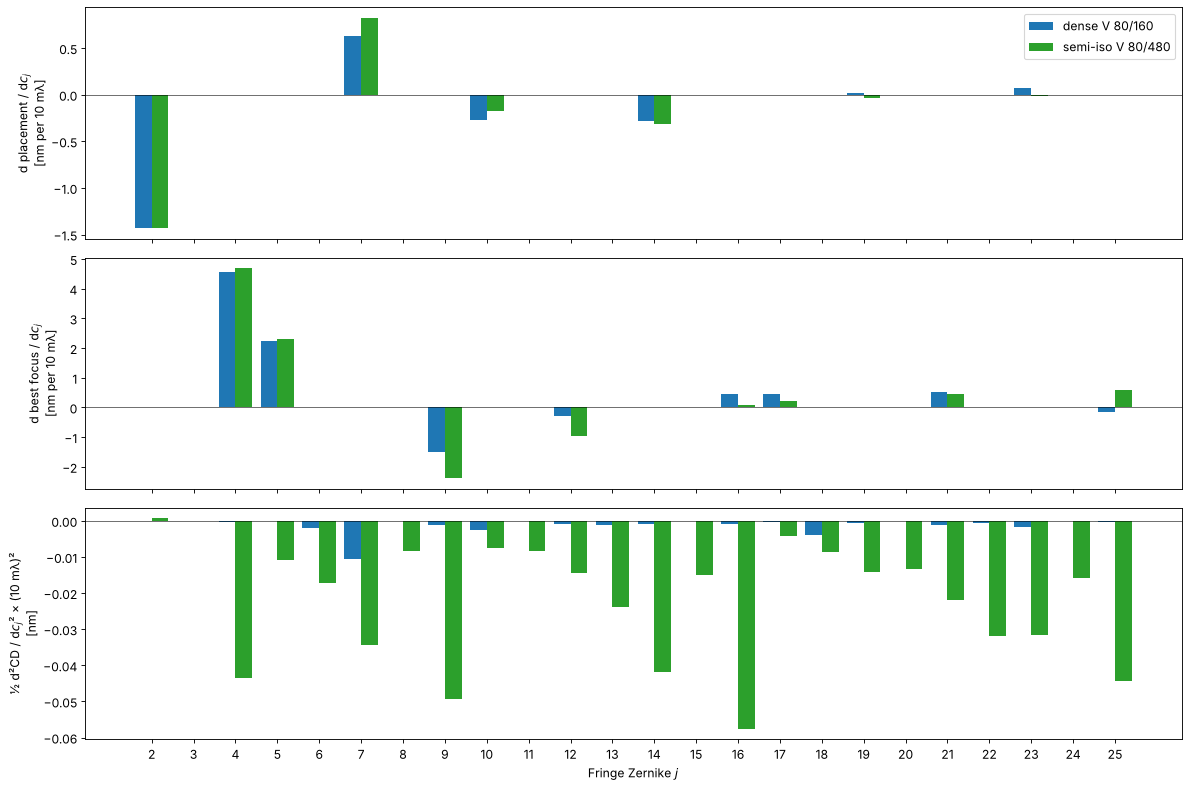

In [7]:
ideal = Projector(NA, WL, n=WATER_ARF, magnification=8.0)
terms = np.arange(2, 26)
sens = {}
for name in ("dense V 80/160", "semi-iso V 80/480"):
    s = sims[name].with_(projector=ideal)
    sens[name] = lens.zernike_sensitivity(s, terms, delta=0.02, dose=s.dose_to_size(threshold=0.3), foci=foci)

fig, axes = plt.subplots(3, 1, figsize=(15, 10), sharex=True)
panels = [("linear", "placement", "d placement / d$c_j$\n[nm per 10 mλ]"),
          ("linear", "best_focus", "d best focus / d$c_j$\n[nm per 10 mλ]"),
          ("quadratic", "cd", "½ d²CD / d$c_j$² × (10 mλ)²\n[nm]")]
for ax, (order, key, yl) in zip(axes, panels):
    for k, (name, s) in enumerate(sens.items()):
        v = getattr(s, order)[key]*(0.01 if order == "linear" else 0.5*0.01**2)
        ax.bar(terms + (k - 0.5)*0.4, v, 0.4, label=name, color=f"C{2*k}")
    ax.set_xticks(terms); ax.axhline(0, color="k", lw=0.5); ax.set_ylabel(yl)
axes[0].legend(); axes[-1].set_xlabel("Fringe Zernike $j$")
fig.tight_layout()
for name, s in sens.items():
    print(f"{name}: largest |dCD/dc_j| {np.max(np.abs(s.linear['cd'])):.2g} nm per wave")

The bars follow from the symmetry of the pattern and the pupil:

- **Placement** of vertical lines (a cut along $x$) responds only to the
  terms odd in $x$: tilt $Z_2$ (exactly $-\lambda/\mathrm{NA}$ per wave), coma $Z_7$,
  trefoil $Z_{10}$, $Z_{14}$, $Z_{19}$, $Z_{23}$. The even terms leave a symmetric
  pattern symmetric. How much coma shifts the lines depends on where the
  diffraction orders pass the pupil, i.e. on the pitch: placement errors are
  pattern dependent.
- **Best focus** responds to the even terms: defocus $Z_4$, spherical
  aberration $Z_9$, $Z_{16}$, and astigmatism $Z_5$ and $Z_{12}$ (with opposite
  signs for horizontal lines). Spherical aberration moves the best focus of
  dense and isolated lines by different amounts: an iso-dense focus
  difference.
- **CD** has no linear sensitivity at all at best focus (printed below):
  an odd term turns the pattern into its mirror image when its sign
  changes, and an even term acts near best focus like a small defocus,
  whose effect on CD is quadratic. The quadratic sensitivities are much
  larger for the semi-isolated lines, whose spectrum fills the whole pupil.
  A linear CD sensitivity appears only away from best focus, i.e. through
  the focus shifts of the second panel.

## 5. An aberration budget

With the sensitivities, the response to any set of Zernikes is predicted
without a new simulation: $\Delta = \sum_j L_j c_j + \tfrac12 Q_j c_j^2$
(`predict()`). Applied to the lens Zernikes across the slit, against the full
simulation of the static image (Zernikes only, without distortion):

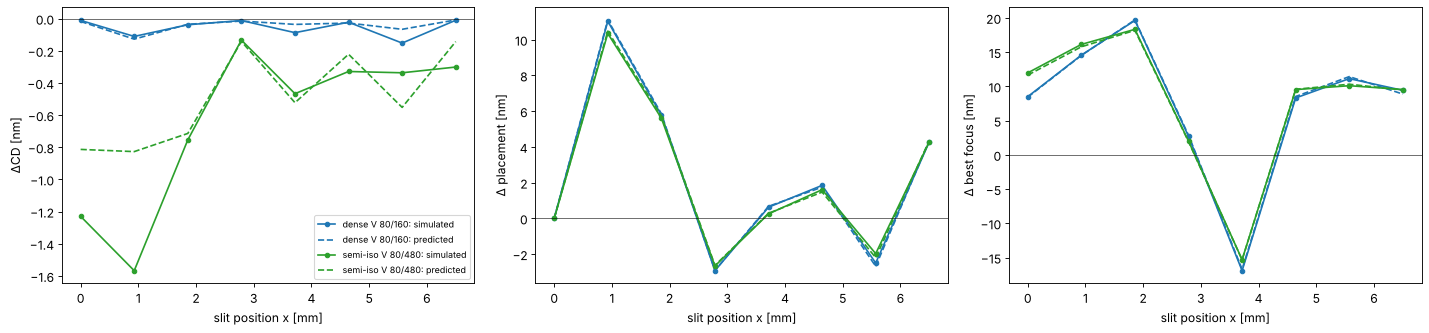

In [8]:
x_fine = np.linspace(0, SLIT_X, 8)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.3))
for k, (name, s) in enumerate(sens.items()):
    sim = sims[name].with_(projector=ideal)
    D = sim.dose_to_size(threshold=0.3)
    sim_r, pred = [], []
    for x in x_fine:
        ab = lens.lens_aberrations(system, (x, 0.0), n_terms=36, N=32)
        r = lens.feature_response(sim.with_(projector=ideal.with_(zernikes=ab.zernikes)), dose=D, foci=foci)
        sim_r.append((r.cd - s.nominal.cd, r.placement - s.nominal.placement, r.best_focus - s.nominal.best_focus))
        p = lens.predict(s, ab.zernikes)
        pred.append((p["cd"], p["placement"], p["best_focus"]))
    sim_r, pred = np.array(sim_r), np.array(pred)
    for i, ax in enumerate(axes):
        ax.plot(x_fine, sim_r[:, i], "o-", color=f"C{2*k}", ms=4, label=f"{name}: simulated")
        ax.plot(x_fine, pred[:, i], "--", color=f"C{2*k}", label=f"{name}: predicted")
for ax, t in zip(axes, ("ΔCD [nm]", "Δ placement [nm]", "Δ best focus [nm]")):
    ax.set_xlabel("slit position x [mm]"); ax.set_ylabel(t); ax.axhline(0, color="k", lw=0.5)
axes[0].legend(fontsize=8)
fig.tight_layout()

Placement and best focus are predicted well: they are mostly linear in the
coefficients. The CD prediction is rougher because CD depends on products
of coefficients (defocus times spherical aberration, astigmatism times
defocus), which the diagonal model leaves out, and this lens's aberrations
(up to about 65 mλ in single terms) are well beyond the ±20 mλ of the
sensitivity steps. For a production lens, with coefficients of a few
milliwaves, the linear budget is the standard tool.

## Summary

- `lens_aberrations()` and `projector_from_system()` hand a ray traced lens
  to the lithography simulation: Zernikes on the projector's pupil,
  distortion, telecentricity and the placement of a small feature.
- Image placement is not chief ray distortion: coma moves the image, and
  by a pattern dependent amount. Scanners correct the linear part
  (`linear_correction()`); the rest is overlay error.
- `through_slit()` gives CD, placement and best focus across the slit,
  averaged over the scan; variations along the scan direction fade the
  image.
- `zernike_sensitivity()` and `predict()` give the linear and quadratic
  sensitivities, their symmetries, and a quick aberration budget.

Exercises: repeat section 3 with an annular or dipole source (the
sensitivities of dense lines change completely), stop the lens down
(`NA=1.2` in `lens_aberrations()`), run the same steps with the dry KrF lens
`caldwell_krf_lens()` (NA 0.56, telecentric), or shift a lens element with
`System.with_axial_shift()` as in notebook 24 and follow the change of best
focus across the slit.